# 03 · Recomendación de pedido y simulación de inventario

Fase 4 de DECISIONES.md (§14). Código en `src/inventario.py` (simulación) y `src/pedido.py` (pedido real); decisiones
en LOG_DECISIONES #25.

**Política order-up-to** con revisión mensual (R = 1) y ventana de protección R + L = h = 3. Al cierre del mes T:
`Q = max(0, pronóstico de T+1…T+3 + SS − (on-hand + tránsito))`. El pedido llega al cierre de T+2 y surte T+3.
El pronóstico de la ventana suma los pronósticos h = 3 ya emitidos para cada mes, así que todo usa datos ≤ T.

| Supuesto | Valor | Por qué |
|---|---|---|
| Demanda no surtida | Se pierde (no hay backorder) | Venta a mayoristas: si no hay stock, compran a otro proveedor |
| Arranque | Cada SKU arranca "ideal" (1 mes + SS en mano, tránsito = pronóstico) | No hay libro de inventario histórico (§14) |
| Calentamiento | Se mide en validación ene–jun 2025 (demanda ≤ primer origen de prueba) y en prueba sep-2025 → sep-2026; jul–ago 2025 usan el periodo puente del backtest | Que el arranque ideal no pese y que la política no se elija con datos posteriores |
| Pronóstico | `TD_estado` para los maduros (según el estado de la familia en el origen: `TD_mix_k3` en caída, `TD_mix_k12` en subida, `ML_base` estable; `02_modelos` §3.8), `Media_post` (jóvenes), 0 si el SKU está dormido (≥ 12 meses sin venta; repuesto que puede volver). Se compara con `ML_base`, la ruta clásica, MA12 y SNaive | LOG #24 y #45 |
| Mes de lanzamiento | Fuera de la política | Lo cubre el pedido inicial de comercial (LOG #24) |
| Valor | Precio MXN mediano del SKU (sep-2024 → sep-2026) | `precio_sku_mes.parquet` |
| Limitación | La demanda observada ya está censurada por quiebres históricos | Solo se ven ventas, no demanda no atendida |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from estilo import aplicar, COLORES, AZUL, GRIS, GRIS_CLARO, FMT_MILES
import inventario as iv

aplicar()
pd.set_option("display.width", 200, "display.max_columns", 40)
RES = RAIZ / "data" / "processed" / "resultados"
FIG = RAIZ / "reports" / "figuras"
r = pd.read_csv(RES / "inv_simulacion.csv")
r_abc = pd.read_csv(RES / "inv_simulacion_abc.csv")
MODELOS = iv.MODELOS
COLOR = dict(zip(MODELOS, [AZUL, COLORES[3], COLORES[1], COLORES[2], GRIS]))
POL = MODELOS[0]                       # modelo de la política elegida (TD_estado, LOG #45)

## 1. Curva de servicio vs inventario (prueba)

Cada punto es un nivel de servicio objetivo α (80 / 90 / 95 / 98 %). Más a la izquierda y más arriba es mejor.
La línea punteada es el SS normal con `ML_base`, como referencia.

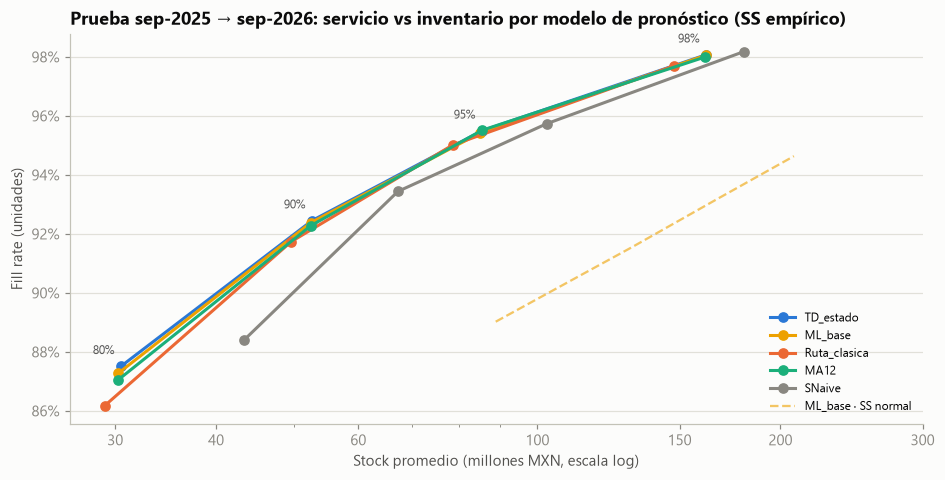

In [2]:
emp = r[(r.metodo == "empirico") & (r.nivel != "ABC 95/90/80")].assign(nivel=lambda d: d.nivel.astype(float))
fig, ax = plt.subplots(figsize=(10, 4.6))
for m in MODELOS:
    g = emp[(emp.periodo == "prueba") & (emp.modelo == m)].sort_values("nivel")
    ax.plot(g.stock_prom_mxn / 1e6, g.fill_rate, marker="o", ms=6, lw=2, color=COLOR[m], label=m)
nm = r[(r.periodo == "prueba") & (r.modelo == "ML_base") & (r.metodo == "normal")].sort_values("stock_prom_mxn")
ax.plot(nm.stock_prom_mxn / 1e6, nm.fill_rate, ls="--", lw=1.5, color=COLOR["ML_base"], alpha=.6, label="ML_base · SS normal")
g = emp[(emp.periodo == "prueba") & (emp.modelo == POL)]
for _, f in g.iterrows():
    ax.annotate(f"{f.nivel:.0%}", (f.stock_prom_mxn / 1e6, f.fill_rate), xytext=(-4, 8), textcoords="offset points",
                fontsize=8, ha="right", color="#555555")
ax.set_xscale("log"); ax.set_xticks([30, 40, 60, 100, 150, 200, 300])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}")); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("Stock promedio (millones MXN, escala log)"); ax.set_ylabel("Fill rate (unidades)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Prueba sep-2025 → sep-2026: servicio vs inventario por modelo de pronóstico (SS empírico)")
ax.legend(fontsize=8, loc="lower right")
fig.savefig(FIG / "21_servicio_vs_inventario.png"); plt.show()

### 1.1 Stock necesario a igual fill rate (interpolado sobre la curva empírica, millones MXN)

In [3]:
def a_igual_servicio(per):
    out = {}
    for m, g in emp[emp.periodo == per].groupby("modelo"):
        g = g.sort_values("fill_rate")
        out[m] = {f"fill {f:.0%}": np.exp(np.interp(f, g.fill_rate, np.log(g.stock_prom_mxn))) / 1e6
                  for f in [.90, .93, .95, .97]}
    t = pd.DataFrame(out).T
    rel = ((t / t.loc["ML_base"] - 1) * 100).round(0).astype(int).astype(str) + " %"
    return t.round(1).join(rel.add_suffix(" vs ML"))
for per in ["validacion", "prueba"]:
    print(per); print(a_igual_servicio(per).to_string()); print()

validacion
              fill 90%  fill 93%  fill 95%  fill 97% fill 90% vs ML fill 93% vs ML fill 95% vs ML fill 97% vs ML
MA12              33.3      42.9      52.8      72.5           -6 %           -1 %           -4 %            1 %
ML_base           35.4      43.3      54.7      71.7            0 %            0 %            0 %            0 %
Ruta_clasica      31.6      40.3      49.0      69.6          -11 %           -7 %          -11 %           -3 %
SNaive            48.8      52.8      61.4      80.1           38 %           22 %           12 %           12 %
TD_estado         36.9      43.6      56.1      76.9            4 %            1 %            3 %            7 %

prueba
              fill 90%  fill 93%  fill 95%  fill 97% fill 90% vs ML fill 93% vs ML fill 95% vs ML fill 97% vs ML
MA12              41.3      58.4      79.1     125.0            2 %            1 %            0 %            0 %
ML_base           40.6      57.8      79.4     124.9            0 %          

## 2. Política elegida: `TD_estado` + SS empírico

In [4]:
cols = ["periodo", "metodo", "nivel", "fill_rate", "fill_rate_mxn", "pct_meses_quiebre", "cobertura_meses",
        "stock_prom_mxn", "venta_perdida_mxn", "stock_riesgo_mxn"]
t = r[(r.modelo == POL) & (r.metodo != "normal")][cols].copy()
for c in ["stock_prom_mxn", "venta_perdida_mxn", "stock_riesgo_mxn"]:
    t[c] = (t[c] / 1e6).round(1)
print("Montos en millones MXN; venta perdida y stock son promedios mensuales; stock en riesgo = cierre de sep-2026")
print(t.sort_values(["periodo", "metodo"]).round(3).to_string(index=False))

Montos en millones MXN; venta perdida y stock son promedios mensuales; stock en riesgo = cierre de sep-2026
   periodo   metodo        nivel  fill_rate  fill_rate_mxn  pct_meses_quiebre  cobertura_meses  stock_prom_mxn  venta_perdida_mxn  stock_riesgo_mxn
    prueba empirico          0.8      0.875          0.855              0.189            2.077            30.5                2.1               1.9
    prueba empirico          0.9      0.924          0.920              0.093            3.582            52.6                1.2               2.6
    prueba empirico         0.95      0.955          0.957              0.045            5.814            85.3                0.6               3.6
    prueba empirico         0.98      0.981          0.983              0.014           11.020           161.8                0.3               6.2
    prueba empirico ABC 95/90/80      0.932          0.933              0.123            4.770            70.0                1.0               2.3
    

### 2.1 ¿Nivel de servicio diferenciado por ABC (A 95 %, B 90 %, C 80 %)?

Es la práctica clásica. Se compara contra un nivel uniforme con el mismo fill rate.

In [5]:
for per in ["validacion", "prueba"]:
    a = r[(r.periodo == per) & (r.modelo == POL) & (r.nivel == "ABC 95/90/80")].iloc[0]
    g = emp[(emp.periodo == per) & (emp.modelo == POL)].sort_values("fill_rate")
    uni = np.exp(np.interp(a.fill_rate, g.fill_rate, np.log(g.stock_prom_mxn)))
    print(f"{per}: ABC → fill {a.fill_rate:.1%} con {a.stock_prom_mxn / 1e6:.1f} M MXN · "
          f"uniforme al mismo fill → {uni / 1e6:.1f} M MXN ({a.stock_prom_mxn / uni - 1:+.0%})")

validacion: ABC → fill 95.3% con 62.2 M MXN · uniforme al mismo fill → 58.3 M MXN (+7%)
prueba: ABC → fill 93.2% con 70.0 M MXN · uniforme al mismo fill → 59.1 M MXN (+18%)


### 2.2 Por segmento ABC (prueba)

In [6]:
s = r_abc[(r_abc.periodo == "prueba") & (r_abc.modelo == POL) & (r_abc.metodo == "empirico")
          & r_abc.nivel.isin(["0.9", "0.95"])]
s = s.assign(stock_prom_mxn=s.stock_prom_mxn / 1e6)
print(s.pivot_table(index="abc", columns="nivel", values=["fill_rate", "pct_meses_quiebre", "cobertura_meses",
                                                         "stock_prom_mxn"]).round(3).to_string())

        cobertura_meses         fill_rate        pct_meses_quiebre        stock_prom_mxn        
nivel               0.9    0.95       0.9   0.95               0.9   0.95            0.9    0.95
abc                                                                                             
A                 2.938   4.773     0.946  0.968             0.064  0.029         32.367  52.581
B                 5.019   8.061     0.905  0.953             0.083  0.032         11.148  17.905
C                 5.370   8.878     0.778  0.851             0.119  0.063          6.721  11.110
sin_ABC          12.303  19.742     0.920  0.968             0.144  0.087          2.333   3.744


### 2.3 Evolución mensual (prueba)

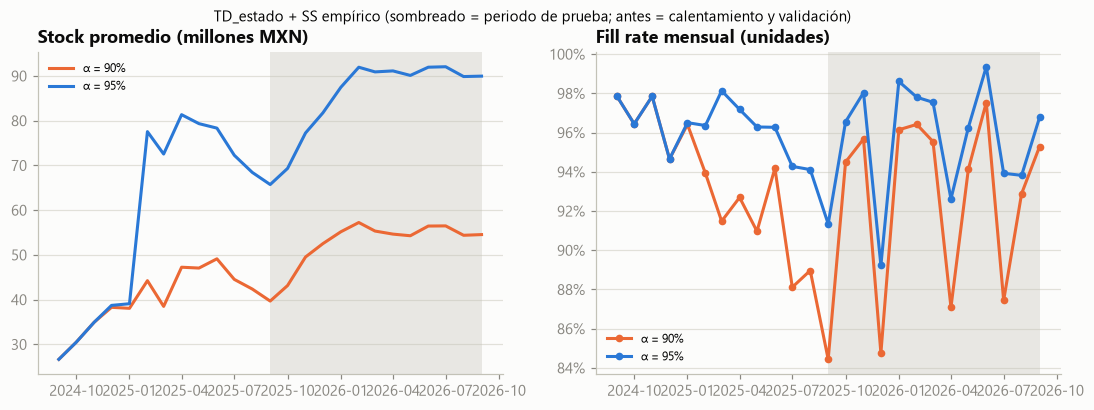

In [7]:
ins = iv.Insumos(POL)
m = np.arange(iv.M0, iv.M1 + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, col in [(.90, COLORES[1]), (.95, AZUL)]:
    dem, ven, inv, ped = iv.simular(ins, "empirico", a)
    ax[0].plot(iv.MESES[m], (inv[:, m] * ins.precio[:, None]).sum(0) / 1e6, color=col, lw=2, label=f"α = {a:.0%}")
    ax[1].plot(iv.MESES[m], ven[:, m].sum(0) / np.maximum(dem[:, m].sum(0), 1), color=col, lw=2, marker="o", ms=4,
               label=f"α = {a:.0%}")
for x in ax:
    x.axvspan(pd.Timestamp("2025-09-01"), pd.Timestamp("2026-09-01"), color=GRIS_CLARO, alpha=.35, lw=0)
    x.legend(fontsize=8)
ax[0].set_title("Stock promedio (millones MXN)"); ax[1].set_title("Fill rate mensual (unidades)")
ax[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle(f"{POL} + SS empírico (sombreado = periodo de prueba; antes = calentamiento y validación)", fontsize=10)
fig.savefig(FIG / "22_evolucion_inventario.png"); plt.show()

## 3. Pedido recomendado (cierre de sep-2026 → llega fin de nov-2026, surte dic-2026)

`reports/pedido_recomendado_2026-09.csv` trae, por SKU, el pronóstico de cada mes de la ventana, el SS y el nivel
objetivo S al 90 y 95 %.

**Stock en mano (LOG #30):** es la suma de todos los almacenes del catálogo (`ICM*`, `AL*`, `extranjero`), con foto
del **21-may-2026**. No hay recepciones ni órdenes abiertas, así que el on-hand al cierre de sep se acota por abajo:
`onhand_min_sep = max(0, stock 21-may − venta real 21-may…sep)`. Por eso `Q_*_max` es una **cota superior**.

In [8]:
p = pd.read_csv(RAIZ / "reports" / "pedido_recomendado_2026-09.csv", index_col=0)
print(f"{len(p)} SKUs")
print(p[["ventana", "S_90", "S_95", "stock_21may", "venta_21may_sep", "onhand_min_sep", "Q_90_max", "Q_95_max"]]
      .sum().round(0).to_string())
print()
for n in (90, 95):          # escenario opuesto: el stock se mantuvo en el nivel de mayo (recepciones ≈ venta)
    print(f"Q_{n} si el stock se mantuvo como en mayo: {np.maximum(p[f'S_{n}'] - p.stock_21may, 0).sum():,.0f}")
print()
print(p.groupby("abc")[["ventana", "S_90", "stock_21may", "onhand_min_sep", "Q_90_max"]].sum().round(0).to_string())

906 SKUs
ventana            344878.0
S_90               568978.0
S_95               738319.0
stock_21may        760190.0
venta_21may_sep    513569.0
onhand_min_sep     334965.0
Q_90_max           416440.0
Q_95_max           562236.0

Q_90 si el stock se mantuvo como en mayo: 111,832
Q_95 si el stock se mantuvo como en mayo: 218,305

          ventana      S_90  stock_21may  onhand_min_sep  Q_90_max
abc                                                               
A        255367.0  410308.0     431963.0        110775.0  331118.0
B         55184.0   93434.0     138878.0         74537.0   56960.0
C         30346.0   55458.0     157887.0        122368.0   22609.0
sin_ABC    3980.0    9778.0      31462.0         27285.0    5753.0


### 3.1 Diagnóstico del stock real (21-may-2026)

Cobertura de cada SKU = stock ÷ venta mensual media de los últimos 12 meses (jun-2025 → may-2026). El valor usa el
mismo precio mediano que la simulación. Se compara con el on-hand simulado de la política al inicio de jun-2026.

In [9]:
import features as ft
from features import MESES

datos = ft.Datos.cargar()
cat = pd.read_csv(RAIZ / "data" / "cat_articulos_202610010754.csv", encoding="latin-1").set_index("id_articulo")
stock = cat[["extranjero", "AL00001", "AL00002", "ICM01", "ICM02", "ICM03", "ICM04", "ICM06", "ICM07", "ICM08"]] \
    .fillna(0).sum(axis=1)
y = pd.DataFrame(np.nan_to_num(datos.y), index=datos.skus, columns=MESES)
im = MESES.get_loc(pd.Timestamp("2026-05-01"))
d = pd.DataFrame({"stock": stock}).join(pd.DataFrame({"v12": y.iloc[:, im - 11:im + 1].mean(axis=1)}), how="outer").fillna(0)
precio = pd.read_parquet(RAIZ / "data" / "processed" / "precio_sku_mes.parquet")
precio = precio[precio.mes >= MESES[iv.M0]].groupby("id_articulo").precio_mxn.median()
d["valor"] = d.stock * precio.reindex(d.index).fillna(precio.median())
d["venta_mxn"] = d.v12 * precio.reindex(d.index).fillna(precio.median())
print(f"Stock real: {d.stock.sum():,.0f} u. · {d.valor.sum() / 1e6:.1f} M MXN · "
      f"cobertura {d.valor.sum() / d.venta_mxn.sum():.1f} meses de venta (valor)")
s = d[d.stock > 0]
cob = s.stock / s.v12.replace(0, np.nan)
seg = pd.cut(cob, [0, 1, 3, 6, 12, np.inf], labels=["< 1", "1–3", "3–6", "6–12", "> 12"]) \
    .cat.add_categories("sin venta 12 m").fillna("sin venta 12 m")
t = s.assign(cobertura=seg).groupby("cobertura", observed=False).agg(skus=("stock", "size"), unidades=("stock", "sum"),
                                                                     M_MXN=("valor", "sum"))
t["M_MXN"] = (t.M_MXN / 1e6).round(1)
t["%_valor"] = (t.M_MXN / t.M_MXN.sum() * 100).round(0)
print(t.to_string())

ins = iv.Insumos(POL, datos)
ij = MESES.get_loc(pd.Timestamp("2026-06-01"))
for a in (.90, .95):
    dem, ven, inv, ped = iv.simular(ins, "empirico", a)
    oh = inv[:, ij] + ven[:, ij] / 2
    print(f"Política simulada {a:.0%}: on-hand inicio jun-2026 {oh.sum():,.0f} u. · {(oh * ins.precio).sum() / 1e6:.1f} M MXN")

Stock real: 762,747 u. · 106.5 M MXN · cobertura 7.2 meses de venta (valor)
                skus  unidades  M_MXN  %_valor
cobertura                                     
< 1               60    2116.0    0.4      0.0
1–3               70   31442.0    4.6      4.0
3–6              145  234238.0   26.8     25.0
6–12             178  229845.0   26.5     25.0
> 12             314  262521.0   47.6     45.0
sin venta 12 m    89    2585.0    0.6      1.0


Política simulada 90%: on-hand inicio jun-2026 393,836 u. · 63.9 M MXN


Política simulada 95%: on-hand inicio jun-2026 576,291 u. · 99.6 M MXN


### 3.2 ¿90 % o 95 %? Margen bruto de equilibrio

No hay dato del costo de mantener inventario (LOG #30), así que se invierte la pregunta: ¿desde qué margen bruto
conviene subir el nivel de servicio? Subir de α₁ a α₂ conviene si

`margen × Δ venta perdida mensual > (h / 12) × (1 − margen) × Δ stock promedio`

con el stock valuado a precio de venta (el costo es precio × (1 − margen)) y h = costo anual de mantener inventario
(capital + almacén + obsolescencia; 20–30 % es un rango típico de referencia). Solo cuenta el margen inmediato de la
venta perdida, no la pérdida del cliente.

In [10]:
g = r[(r.modelo == POL) & (r.metodo == "empirico") & (r.nivel.isin(["0.8", "0.9", "0.95", "0.98"]))].copy()
g["nivel"] = g.nivel.astype(float)
filas = []
for per, x in g.groupby("periodo"):
    x = x.sort_values("nivel")
    for (_, a), (_, b) in zip(x.iterrows(), x.iloc[1:].iterrows()):
        k = (b.stock_prom_mxn - a.stock_prom_mxn) / (12 * (a.venta_perdida_mxn - b.venta_perdida_mxn))
        fila = {"periodo": per, "paso": f"{a.nivel:.0%} → {b.nivel:.0%}",
                "Δ stock (M MXN)": (b.stock_prom_mxn - a.stock_prom_mxn) / 1e6,
                "Δ venta perdida/mes (M MXN)": (a.venta_perdida_mxn - b.venta_perdida_mxn) / 1e6}
        for h in (.15, .20, .25, .30):
            fila[f"margen mín. h={h:.0%}"] = f"{h * k / (1 + h * k):.0%}"
        filas.append(fila)
print(pd.DataFrame(filas).round(2).to_string(index=False))

   periodo      paso  Δ stock (M MXN)  Δ venta perdida/mes (M MXN) margen mín. h=15% margen mín. h=20% margen mín. h=25% margen mín. h=30%
    prueba 80% → 90%            22.08                         0.96               22%               28%               32%               37%
    prueba 90% → 95%            32.77                         0.54               43%               50%               56%               60%
    prueba 95% → 98%            76.41                         0.38               71%               77%               81%               83%
validacion 80% → 90%            13.51                         0.78               18%               22%               27%               30%
validacion 90% → 95%            27.33                         0.50               40%               48%               53%               58%
validacion 95% → 98%            68.34                         0.41               67%               73%               78%               81%


## 4. Hallazgos

0. **Modelo de la política: `TD_estado` (LOG #45).** Es el pronóstico con menor WAPE y sesgo de los SKUs maduros
   (`02_modelos` §3.8: prueba 0.482 y +1.6 %, contra 0.490 y +3.5 % de `ML_base`). **En inventario empata con
   `ML_base`:** a igual fill rate necesita 1 % menos stock en prueba y 1–7 % más en validación (1.1). El SS empírico se
   calibra con los errores de ventana de cada modelo y absorbe el sesgo, así que la mejora del pronóstico central no
   se traduce en menos stock. Su valor está en que el pronóstico que ven comercial y compras es más fiel.
1. **El stock de seguridad empírico funciona y está bien calibrado.** El nivel objetivo α se cumple casi exacto:
   con α = 95 % el fill rate es 95.5 % en prueba y 96.8 % en validación; con 90 %, 92.4 % y 93.2 %. El **SS normal
   no sirve**: con `ML_base` al 95 % da un fill de 93.2 % con 167 M MXN de stock en prueba, contra 95.4 % con 85 M
   del empírico. Con los errores de la ruta clásica explota a 35–117 meses de cobertura. Esto confirma §14: con
   demanda intermitente y asimétrica no se usa la fórmula normal. El empírico además absorbe el sesgo del modelo
   sin un factor ad hoc.
2. **Sin SS no alcanza:** solo con el pronóstico, el fill rate queda en 80 % y hay quiebre en el 31 % de los
   SKU-mes con demanda.
3. **El servicio cuesta de forma no lineal.** En prueba, pasar de 90 % a 95 % de fill rate sube el stock 62 % (de 53
   a 85 M MXN, de 3.6 a 5.8 meses de cobertura en valor). Pasar de 95 % a 98 % lo casi duplica (162 M). El nivel de
   servicio es una **decisión de negocio**: compara el margen perdido contra el costo de mantener inventario.
4. **El modelo de pronóstico mueve poco el inventario total.** A igual fill rate, `TD_estado`, `ML_base`, la ruta
   clásica y MA12 necesitan stock parecido (±3 % en prueba; en validación la ruta clásica fue 3–11 % más barata).
   SNaive sí cuesta 10–38 % más. La ventaja del ML a nivel SKU se concentra en SKUs chicos e intermitentes, que pesan
   poco en valor; en los SKUs A, que dominan el inventario, los modelos empatan. Donde el ML sí gana es en
   **stock sin rotación**: al 95 % deja 3.6 M MXN de stock en riesgo (SKUs sin venta en 6 meses; parte es repuesto
   que se conserva a propósito), igual con `TD_estado` y `ML_base`, contra 4.6 M de la ruta clásica, 3.9 M de MA12 y
   5.6 M de SNaive.
5. **El servicio diferenciado por ABC (A 95 / B 90 / C 80) no conviene:** cuesta 7 % (validación) y 18 % (prueba) más
   stock que un nivel uniforme con el mismo fill rate. Los SKUs A son los que más valen, así que subirles el servicio
   es lo más caro. Se recomienda un **nivel uniforme**.
6. **Por segmento (α = 95 %, prueba):** A logra 96.8 % de fill con 4.8 meses de cobertura. C solo llega a 85.1 %
   con 8.9 meses (son intermitentes: mucho stock y aun así quiebres). Los SKUs nuevos (sin ABC) quedan con ~20
   meses de cobertura: el SS de la clase "joven" compensa de más el sub-pronóstico de `Media_post`. Pesa poco en
   valor (3.7 M MXN), pero es un ajuste pendiente.
7. **Pedido de sep-2026 (`TD_estado`):** la ventana oct-2026 → dic-2026 (h = 3) suma 345 mil unidades. El nivel
   objetivo es 569 mil al 90 % y 738 mil al 95 %. La foto de stock es del 21-may (760 mil u. en todos los almacenes)
   y no hay recepciones ni órdenes abiertas, así que el pedido solo se puede acotar:
   - **Máximo** (cero recepciones jun–sep): 416 mil al 90 % y 562 mil al 95 %.
   - **Si el stock se mantuvo como en mayo:** 112 mil al 90 % y 218 mil al 95 %.
   - Para afinarlo hace falta el stock al cierre de sep-2026.
8. **El stock real ya es alto, pero está mal repartido.** El 21-may había 106.5 M MXN (7.2 meses de venta), más que
   la política simulada al 95 % (100 M al inicio de jun-2026). El **45 % del valor está en SKUs con más de 12 meses
   de cobertura**, y 437 SKUs tienen más stock que su S al 95 %, con unas 240 mil unidades de exceso. La política
   reparte el stock según el error de cada clase, así que el mismo dinero daría más servicio.
9. **Nivel de servicio:** con el margen de equilibrio (3.2), subir de 90 % a 95 % solo conviene con márgenes brutos
   altos: más de ~50–56 % según la prueba, o más de ~48–53 % según la validación, con h = 20–25 %. Subir de 80 % a
   90 % conviene desde ~22–32 %. Con márgenes típicos de distribución de electrónica (< 35 %), **se recomienda 90 %**,
   salvo que la venta perdida tenga un costo extra (pérdida del cliente) que no se mide aquí.
10. **Limitaciones:** sin órdenes abiertas ni libro de inventario, el arranque es ideal. Se supone venta perdida.
   La demanda observada ya viene censurada por quiebres pasados, así que el fill rate real podría ser un poco menor.
   El valor usa un precio mediano por SKU.